# Revision-Aware Repair Verification (RARV)
### Gemma 4 Developer Agent Paper Track — CPU reproducibility companion (v2.6)

**Author:** Clifford Imaguezegie  
**Purpose:** Understand the implemented verification framework, independently execute its CPU controller replay, and reconstruct the published evaluation results.  
**Execution:** Three clearly labelled, readable code cells: one to render the architecture and framework, one to run the E17 CPU checks, and one to inspect the real implementation source. Select **Run All** in this order. The diagram cell needs only standard notebook plotting libraries; the optional source-inspection cell needs E17 extracted by the CPU reproduction cell. Neither needs the Gemma model or competition datasets. There is no encoded Python or Base64 source payload.

**Kaggle execution provenance (Version 3):** The author supplied the successful hosted **Kaggle Notebook Version 3** CPU run on **Python 3.13.18**. It found E17 as an extracted directory, verified the **29 original files**, and passed the frozen-controller replay and archive-result reconciliation with **six trusted pytest executions and zero model calls**. This is an independently hosted compatibility replay, **not the original Python 3.12 study run**.

**Kaggle CPU input already supplied:**
`/kaggle/input/datasets/cliffordimaguezegie/gemma4-rarv-evidence`

The companion looks for `Gemma4_RARV_CPU_Review_Package_v1_0.zip` in that mounted dataset **first**, verifies its SHA-256, and runs **offline**. Kaggle Internet access is **not required**.

> **Important — original competition inputs:** The **17 implementation notebooks (GP00–GP05)** use the original **Google — The Gemma 4 Developer Agent Competition** dataset, snapshots and supporting inputs. Those are **separate from E17**. To execute the research implementation notebooks, attach the original competition dataset, the requested wheels/fixtures, and the pinned Gemma 4 model as applicable (see **Implementation prerequisites** below). The E17 CPU reviewer check itself needs only E17, Python 3.10+ and Git.

**Reviewer links:** [Live Kaggle Companion](https://www.kaggle.com/code/cliffordimaguezegie/gemma4-revision-aware-repair-verification) · [Public E17 dataset](https://www.kaggle.com/datasets/cliffordimaguezegie/gemma4-rarv-evidence) · [GitHub research repository](https://github.com/clifford-imaguezegie/revision-aware-repair-verification) · [Evidence index](https://github.com/clifford-imaguezegie/revision-aware-repair-verification/blob/main/docs/evidence-index.md)

**Saved-output provenance:** The output cells bundled with this downloadable v2.6 source were inherited from the previously validated **local Python 3.13.5** execution. The **Kaggle Version 3, Python 3.13.18** run reported above is a *separate* hosted verification. For outputs attributable to this exact revised notebook, execute **Run All → Save Version** in Kaggle. The original frozen E17 Python 3.12 evidence and checksums remain unchanged.


## At a glance — study map and reviewer navigation

| Research stage | Cases and purpose | What the companion can verify |
|:--|:--|:--|
| **Development (GP00–GP02)** | **6 development cases** used to construct and qualify the repair/verification workflow | Inspect the [17 implementation notebooks](#implementation-notebooks--complete-linked-catalogue-17) and their retained evidence; full development execution needs the competition inputs |
| **Primary autonomous evaluation (GP03)** | **9 matched B/C task pairs, 18 agent runs**; three tasks each from FastAPI, Requests and Rich | Reconcile **6/9 protected passes for B and C** and **5/9 vs 4/9 verified deliveries** |
| **Autonomous follow-up (GP04–GP05)** | **3 additional matched pairs, 6 agent runs** | Reconcile **1/3 protected passes per policy** (descriptive, not pooled with primary inference) |
| **Separate controlled activation (GP04)** | **2 matched pairs, 4 agent runs** with deliberate post-pass edits | Review C's recorded **1.150 s and 1.047 s** pre-inference detections; CPU fixture demonstrates B `STALE`, C `CURRENT_FAIL` |

**Total evaluation:** **12 distinct autonomous task pairs (24 runs)** plus **2 deliberately triggered controlled pairs (4 runs)**. The six development cases are separate. No natural qualifying pass-to-edit event occurred in the 24 autonomous runs; the CPU demonstration is **not** another autonomous repair run.

**Evidence in this notebook:** E17 CPU replay → **6/6 trusted checks, zero model calls**; archived-outcome reconciliation → **12 original JSON members**, including the complete GP03–GP05 counts and provenance. Fresh protected grading and new Gemma inference remain outside this CPU review.

**Visual navigation:** [Figure A — implemented system architecture](#rarv-architecture) · [Figure B — verification framework](#rarv-framework) · [CPU reproduction](#4-cpu-reproduction-independent-e17-check-no-internet-required) · [Implementation catalogue](#implementation-notebooks--complete-linked-catalogue-17). The two diagrams are rendered by the first code cell.



<a id="rarv-architecture"></a>
## 1. Architecture — *what was implemented and how components connect*

**Architecture** is the structural blueprint of the implemented RARV system: the nondeterministic **Gemma repair worker** proposes actions, while the deterministic **tool supervisor, revision ledger, trusted pytest adapter and B/C controller** observe and validate evidence. The production patch then crosses into a **separate protected-evaluation path**; recorded grades and submission decisions are reconciled by exact attempt/patch identity.

**Figure A** below is generated from readable Matplotlib code in the next cell. It illustrates the architecture of the complete **research workflow**. The E17 CPU review package directly exercises the frozen controller, adapter, ledger and gate; the actual Gemma worker and fresh protected grader are *not* executed by E17.

The diagram is intentionally distinct from the **verification framework** in Figure B: the framework explains how evidence moves through states, policies and gates, rather than merely naming components.


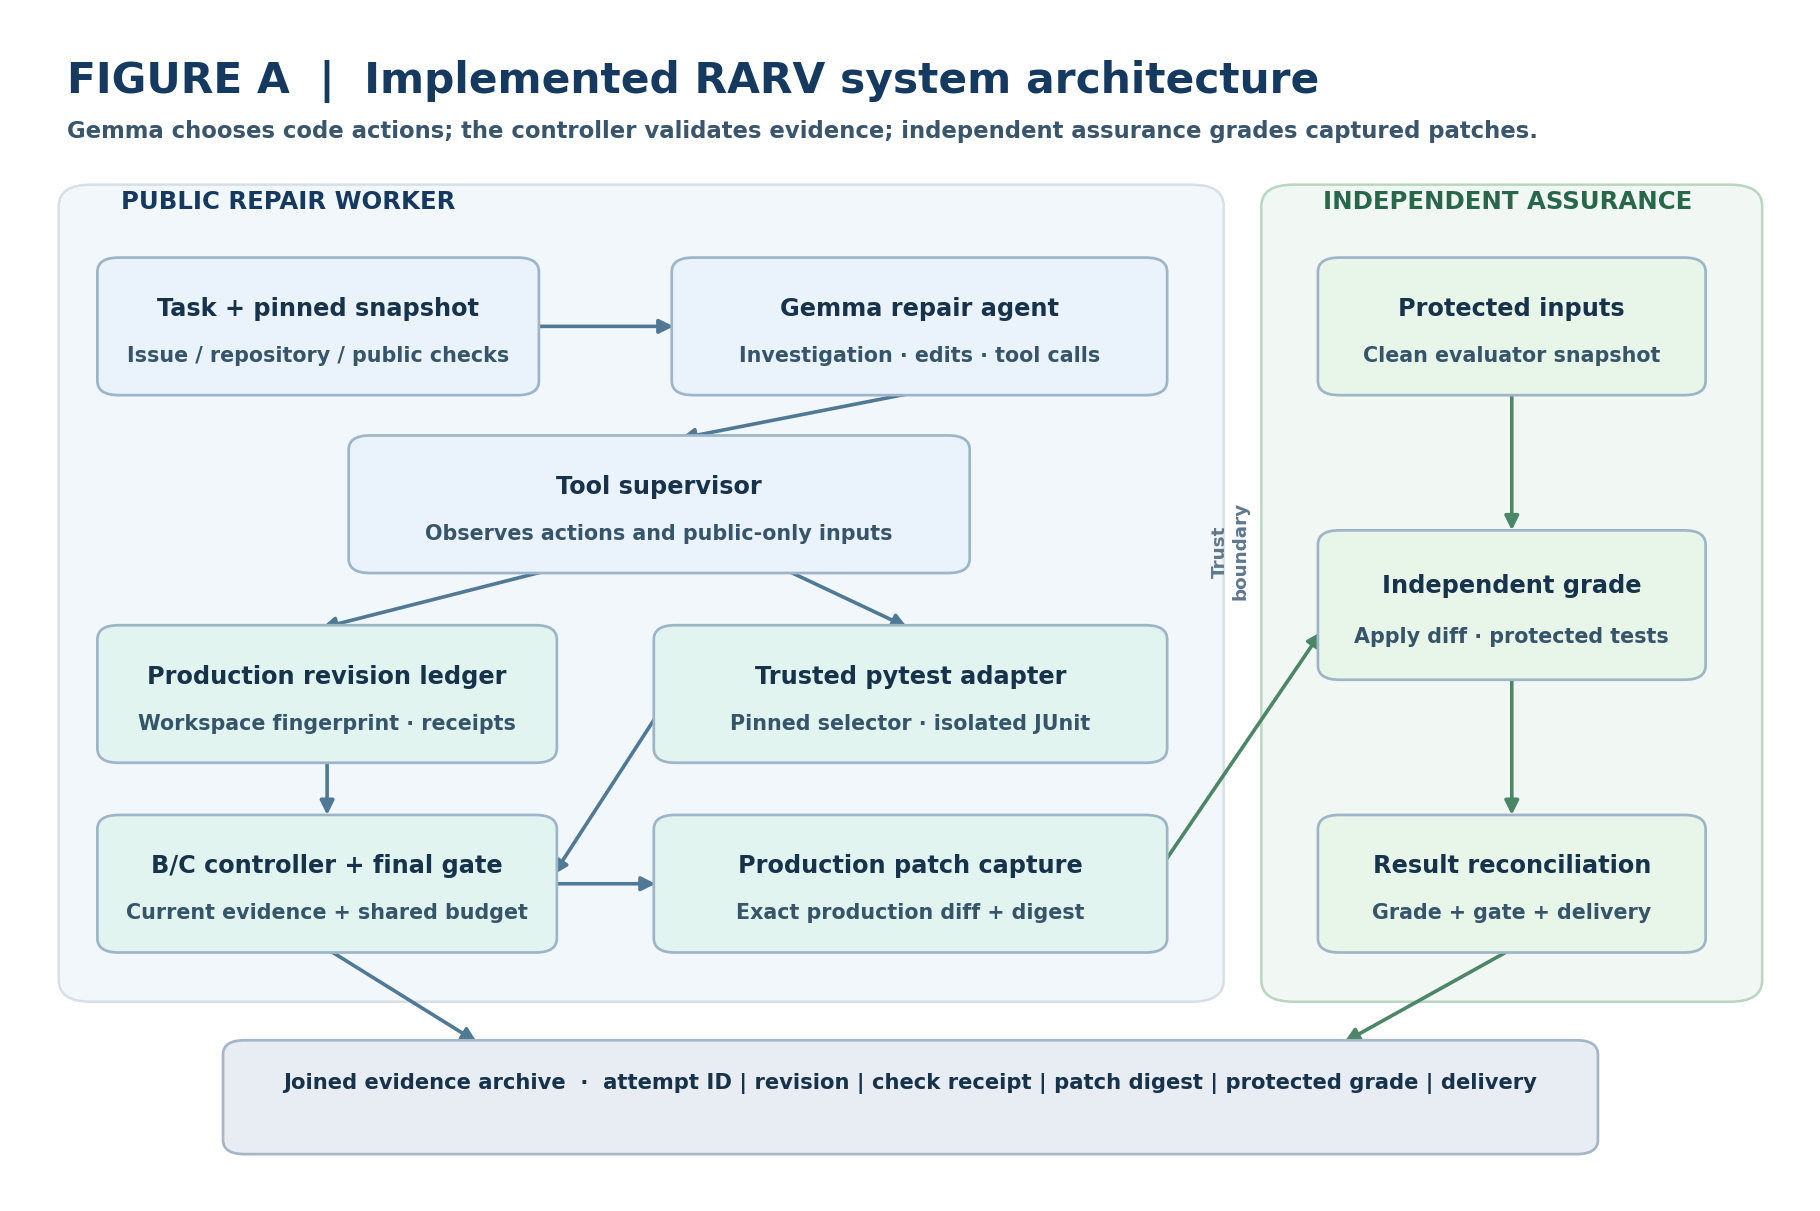

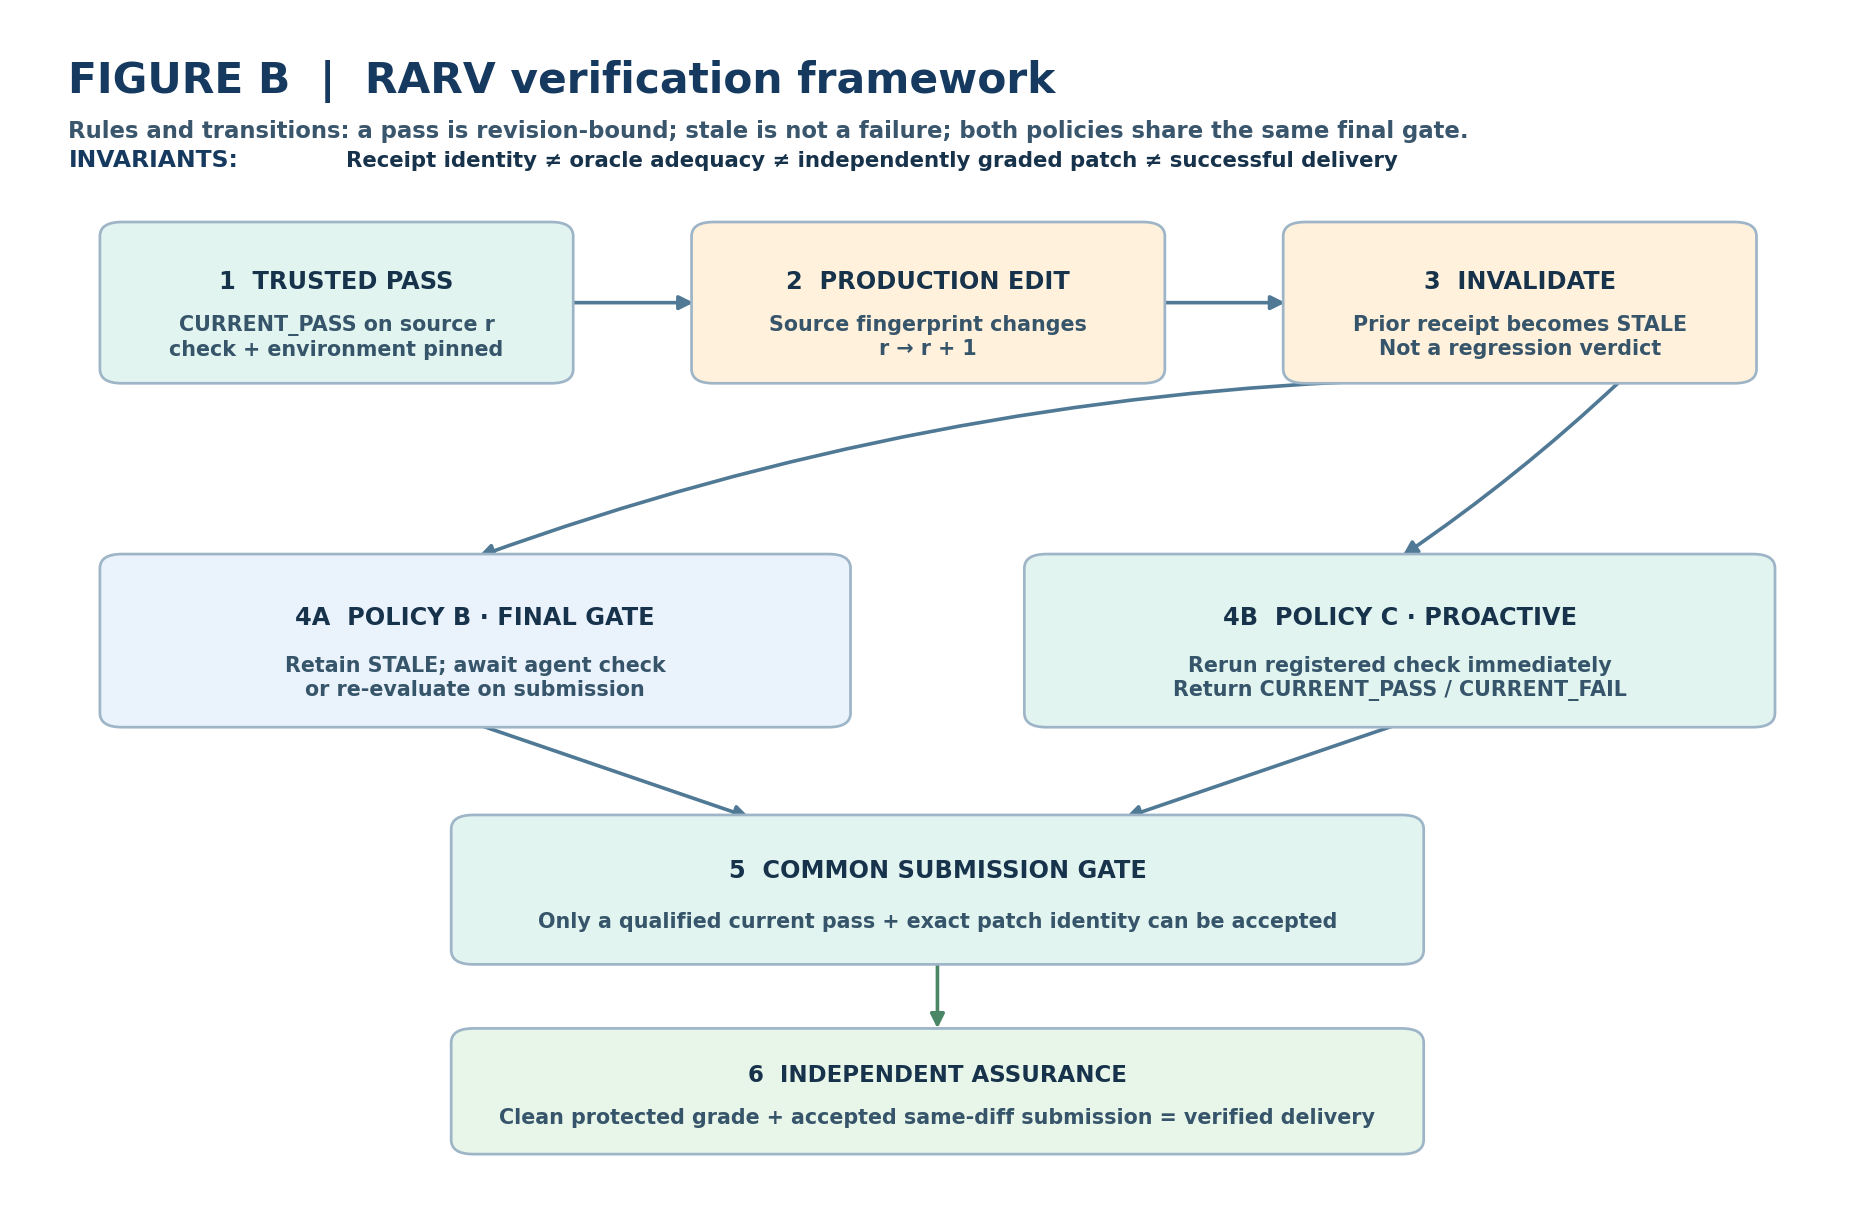

Rendered architecture and framework. Figure files: /kaggle/working/rarv_readable_ewkmqh2r/figures


In [15]:
# VISUAL CELL 1 — RARV architecture + verification framework
# Produces two genuine vector diagrams using readable Python; no embedded payloads.
# CPU-only; matplotlib is included in Kaggle's standard Python environment.
from pathlib import Path
from IPython.display import display, Markdown
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

# Consistent research-paper palette: blue = agent/public path, teal = verified evidence,
# amber = stale/invalidation, pale green = separate independent assurance.
NAVY = '#163A5F'
INK = '#17324B'
BLUE = '#EAF2FC'
TEAL = '#E2F4F0'
AMBER = '#FFF1DC'
GREEN = '#E8F5E9'
WHITE = '#FFFFFF'
EDGE = '#9EB5C8'
BG = '#FBFCFE'


def _canvas(title, subtitle, figsize=(14.5, 9.4)):
    fig, ax = plt.subplots(figsize=figsize, dpi=130)
    fig.patch.set_facecolor(WHITE)
    ax.set_facecolor(WHITE)
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.axis('off')
    ax.text(3, 96, title, fontsize=23.5, fontweight='bold', color=NAVY, va='top')
    ax.text(3, 91, subtitle, fontsize=12.6, fontweight='semibold', color='#39566D', va='top')
    return fig, ax


def _panel(ax, x, y, w, h, fill=BG, edge='#D7E0E9'):
    ax.add_patch(FancyBboxPatch((x,y),w,h,
        boxstyle='round,pad=0.45,rounding_size=1.8',
        linewidth=1.4, facecolor=fill, edgecolor=edge, zorder=0))


def _node(ax, x, y, w, h, title, detail='', fill=BLUE,
          edge=EDGE, title_size=13.3, detail_size=11.4):
    ax.add_patch(FancyBboxPatch((x,y),w,h,
        boxstyle='round,pad=0.3,rounding_size=1.2',
        linewidth=1.5, facecolor=fill, edgecolor=edge, zorder=3))
    ax.text(x+w/2,y+h*0.64,title,ha='center',va='center',
            fontsize=title_size,fontweight='bold',color=INK,zorder=4)
    if detail:
        ax.text(x+w/2,y+h*0.28,detail,ha='center',va='center',
                fontsize=detail_size,fontweight='semibold',color='#36556A',linespacing=1.25,zorder=4)


def _arrow(ax, start, end, color='#507995', rad=0.0, lw=2.0):
    ax.add_patch(FancyArrowPatch(start,end,arrowstyle='-|>',
        mutation_scale=16, linewidth=lw,color=color,
        connectionstyle=f'arc3,rad={rad}',zorder=2))


# FIGURE A — Research system architecture: worker boundary versus protected assurance.
fig_a, a = _canvas('FIGURE A  |  Implemented RARV system architecture',
                    'Gemma chooses code actions; the controller validates evidence; independent assurance grades captured patches.')
_panel(a,3,17,64,68,fill='#F2F7FC')
_panel(a,70,17,27,68,fill='#F1F8F3',edge='#B9D6C2')
a.text(6,83.5,'PUBLIC REPAIR WORKER',fontweight='bold',fontsize=13.5,color=NAVY)
a.text(73,83.5,'INDEPENDENT ASSURANCE',fontweight='bold',fontsize=13.5,color='#28674A')

_node(a,5,68,24,11,'Task + pinned snapshot','Issue / repository / public checks',BLUE)
_node(a,37,68,27,11,'Gemma repair agent','Investigation · edits · tool calls',BLUE)
_node(a,19,53,34,11,'Tool supervisor','Observes actions and public-only inputs',BLUE)
_node(a,5,37,25,11,'Production revision ledger','Workspace fingerprint · receipts',TEAL)
_node(a,36,37,28,11,'Trusted pytest adapter','Pinned selector · isolated JUnit',TEAL)
_node(a,5,21,25,11,'B/C controller + final gate','Current evidence + shared budget',TEAL)
_node(a,36,21,28,11,'Production patch capture','Exact production diff + digest',TEAL)
_node(a,73,68,21,11,'Protected inputs','Clean evaluator snapshot',GREEN)
_node(a,73,44,21,12,'Independent grade','Apply diff · protected tests',GREEN)
_node(a,73,21,21,11,'Result reconciliation','Grade + gate + delivery',GREEN)

_arrow(a,(29,73.5),(37,73.5))
_arrow(a,(50.5,68),(37,64))
_arrow(a,(30,53),(17,48))
_arrow(a,(43,53),(50,48))
_arrow(a,(17.5,37),(17.5,32))
_arrow(a,(36,41),(30,27))
_arrow(a,(30,26.5),(36,26.5))
_arrow(a,(83.5,68),(83.5,56),color='#4B8766')
_arrow(a,(83.5,44),(83.5,32),color='#4B8766')
_arrow(a,(64,28),(73,48),color='#4B8766')

# The two assurance branches are joined in the bottom evidence register.
_node(a,12,4,76,9,'Joined evidence archive  ·  attempt ID | revision | check receipt | patch digest | protected grade | delivery',
      '',fill='#E8EDF3',edge='#A6B6C6',title_size=11.7)
_arrow(a,(17.5,21),(26,13))
_arrow(a,(83.5,21),(74,13),color='#4B8766')
a.text(67.8,50.8,'Trust\nboundary',ha='center',fontsize=10.2,fontweight='semibold',color='#60788D',rotation=90)
fig_a.tight_layout(pad=1.0)
display(fig_a)

# FIGURE B — Verification framework: event-triggered states and decision contract.
fig_b, b = _canvas('FIGURE B  |  RARV verification framework',
                    'Rules and transitions: a pass is revision-bound; stale is not a failure; both policies share the same final gate.')
_node(b,5,69,25,13,'1  TRUSTED PASS','CURRENT_PASS on source r\ncheck + environment pinned',TEAL)
_node(b,37,69,25,13,'2  PRODUCTION EDIT','Source fingerprint changes\nr → r + 1',AMBER)
_node(b,69,69,25,13,'3  INVALIDATE','Prior receipt becomes STALE\nNot a regression verdict',AMBER)
_arrow(b,(30,75.5),(37,75.5))
_arrow(b,(62,75.5),(69,75.5))

_node(b,5,40,40,14,'4A  POLICY B · FINAL GATE','Retain STALE; await agent check\nor re-evaluate on submission',BLUE)
_node(b,55,40,40,14,'4B  POLICY C · PROACTIVE','Rerun registered check immediately\nReturn CURRENT_PASS / CURRENT_FAIL',TEAL)
_arrow(b,(75,69),(25,54),rad=0.08)
_arrow(b,(87,69),(75,54),rad=-0.04)
_node(b,24,20,52,12,'5  COMMON SUBMISSION GATE','Only a qualified current pass + exact patch identity can be accepted',TEAL,title_size=13.3)
_arrow(b,(25,40),(40,32))
_arrow(b,(75,40),(60,32))
_node(b,24,4,52,10,'6  INDEPENDENT ASSURANCE','Clean protected grade + accepted same-diff submission = verified delivery',GREEN,title_size=12.7)
_arrow(b,(50,20),(50,14),color='#4B8766')
b.text(3,87,'INVARIANTS:',fontsize=13.0,fontweight='bold',color=NAVY)
b.text(18,87,'Receipt identity ≠ oracle adequacy ≠ independently graded patch ≠ successful delivery',
       fontsize=11.8,fontweight='semibold',color=INK)
fig_b.tight_layout(pad=1.0)
display(fig_b)

# Export diagrams for further use in documentation, without altering E17 evidence.
if 'run_dir' in globals():
    figure_directory = Path(run_dir) / 'figures'
else:
    figure_directory = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path.cwd()
figure_directory.mkdir(parents=True,exist_ok=True)
fig_a.savefig(figure_directory/'RARV_Architecture.png',dpi=200,bbox_inches='tight',facecolor='white')
fig_b.savefig(figure_directory/'RARV_Framework.png',dpi=200,bbox_inches='tight',facecolor='white')
print('Rendered architecture and framework. Figure files:', figure_directory)
plt.close(fig_a)
plt.close(fig_b)


<a id="rarv-framework"></a>
## 2. The developed framework — *rules and evidence-state lifecycle*

The **RARV framework** is the methodological and executable contract implemented by the architecture:

1. **Observe:** Fingerprint eligible production code before and after an agent tool action. A qualifying edit advances the monotonic revision.
2. **Bind:** Record a trusted pytest outcome with the tested **revision, production digest, registered check definition, environment identity and execution provenance**.
3. **Invalidate:** A subsequent qualifying edit makes an earlier qualified pass **STALE**. Staleness alone is **not** a confirmed regression.
4. **Apply the frozen policy:** **B** defers rechecking until an agent-selected check or submission. **C** proactively re-executes a previously passing registered check after a relevant edit, within the same shared budget, and returns the fresh status to the agent.
5. **Gate:** Both arms require current qualified evidence and an exact production-patch identity for accepted submission.
6. **Assure independently:** Capture eligible production diffs (including deadline candidates), grade patches outside the worker against protected requirements, and distinguish a protected-passing **capture** from **verified delivery** of that same patch.

**Figure B** visualises the B/C state transitions and shared assurance rule. This framework is not a claim that refreshing a receipt makes the selected test relevant or guarantees a correct patch. The controlled experiments verify activation under a deliberately created trigger; naturally occurring qualifying triggers were absent in the 24 autonomous runs.

*Architecture = implemented components and interfaces; framework = state rules, policy decisions and assurance contract implemented through those components.*


## Key research contributions

**C1 — Integrated, revision-aware verification architecture.** An actual implemented controller links code revisions and content digests to trusted test receipts, policy decisions, exact production patch capture, independent grading and accepted delivery. The novelty is the auditable integration of known techniques, **not** an invented testing algorithm or a new state-machine formalism.

**C2 — Matched empirical study of recheck opportunity and activation.** GP03 compared policies B and C on nine preselected task pairs using matched budgets, the same final gate and the same agent configuration. Each policy passed **6/9** protected tasks (paired difference **0.0 percentage points**, 95% bootstrap interval **−22.2 to +22.2**). Across GP03–GP05, **24 autonomous runs contained zero qualifying natural pass-to-edit exposures**. In two deliberately triggered GP04 pairs, C reported failures in **1.150 s** and **1.047 s** before inference. The effect of proactive rechecking *after a naturally occurring trigger* remains unestimated.

**C3 — Empirical distinction among assurance boundaries.** A current receipt does not prove that the test covers the reported defect; a protected-passing candidate does not prove that the patch was submitted. The trace cases include public/protected test disagreements, an injected fault retained despite a protected pass, and protected-passing deadline captures without verified delivery.

**Reproducibility contribution (supporting evidence).** The E17 review package runs the **frozen production controller and trusted adapter** on a synthetic Git fixture and reconciles saved results against SHA-256-pinned archived JSON members. It does **not** rerun Gemma's GPU trajectories or the private protected tests.


## Evaluation coverage and reproducibility boundaries

| Cohort | Task pairs | Agent runs | Protected passes | Verified deliveries |
|:--|--:|--:|:--|:--|
| GP03 primary autonomous | 9 | 18 | B **6/9**, C **6/9** | B **5/9**, C **4/9** |
| GP04 autonomous follow-up | 2 | 4 | B **1/2**, C **1/2** | Neither arm delivered |
| GP05 autonomous follow-up | 1 | 2 | B **0/1**, C **0/1** | Neither arm delivered |
| GP04 deliberate-trigger controlled | 2 | 4 | Captures passed protected suites in both arms | Neither arm delivered |

These cohorts have different starting conditions and denominators. The **primary statistical comparison** is GP03 only. The controlled results demonstrate mechanism activation and should not be pooled into a causal repair-success estimate.


## 4. CPU reproduction: independent E17 check, no Internet required

**E17 Kaggle dataset mount (public reviewer input):** [Open the E17 dataset](https://www.kaggle.com/datasets/cliffordimaguezegie/gemma4-rarv-evidence)

```text
/kaggle/input/datasets/cliffordimaguezegie/gemma4-rarv-evidence
```

1. Set the companion notebook to **CPU**. Use Python 3.10+ and ensure Git is available. The **Kaggle Version 3** CPU replay passed on Python **3.13.18** using the documented compatibility launcher; the frozen study environment was Python **3.12**. The compatibility run does not recreate the original environment fingerprint.
2. Attach the dataset above to the Kaggle notebook. The launcher searches the **provided mount first**, including subdirectories. It accepts either (a) the *original* `Gemma4_RARV_CPU_Review_Package_v1_0.zip`, verified by SHA-256, or (b) the **29 original extracted E17 files**, individually verified against their original SHA-256 hashes. Kaggle may unpack a dataset ZIP during upload. A renamed ZIP is also recognised by its checksum.
3. Run the **E17 reproduction code cell** below (the diagram cell above is optional for CPU verification). It installs the E17 package's pinned, offline, pure-Python pytest wheels in an isolated virtual environment and executes the actual frozen controller and result reconstructor. No network download, Gemma model or extra setup cell is required for **this CPU check**.
4. Read the formatted results table **and the original full replay stdout and JSON displayed below**. Detailed replay, reconciliation and logs are saved under the displayed `/kaggle/working/rarv_readable_...` folder.

**Outputs on opening:** A concise dashboard, the original replay messages, and the full original reconciliation JSON (no fields omitted). The raw evidence is also saved to `Full_Original_Evidence.md`.

**Expected results:** replay `PASS`; six trusted pytest checks; B `STALE` after the production edit; C `CURRENT_FAIL`; both gates block the broken state and accept restoration; GP03 protected passes `6/9` for each policy and verified delivery `5/9` B / `4/9` C; 24 autonomous runs and zero qualifying natural triggers.

**Precise scope:** This CPU review replays controller behaviour on a synthetic Git checkout and reconstructs reported grading outcomes from 12 checksum-pinned archived JSON members. It **does not** re-run GPU repair trajectories, the organiser's protected evaluator, or all 28 original patch-byte checks, which require the seven sealed archives. A non-3.12 compatibility run modifies only a temporary version assertion, *not* the frozen E17 archive.

**For full GP00–GP05 implementation reproduction, the separate competition inputs below are required.** Their presence is checked for reviewer convenience, but missing full-study inputs will **not block this E17 CPU check**.

**If you encounter an input-discovery error:** The cell prints a short listing of the available Kaggle mount directories. Set `E17_PACKAGE_PATH` near the beginning of the cell to the **actual ZIP filename** or the **extracted package directory containing `replay_controller.py`**; never point it only to a parent dataset directory unless the package files sit at that level.


In [16]:
# RUN THIS CELL — E17 CPU replay and archived-result reconciliation (NO prior setup cell)
# Everything here is clear-text Python. The E17 ZIP is a separate, checksum-pinned artifact.
from pathlib import Path
from zipfile import ZipFile
from IPython.display import display, Markdown
import hashlib, json, os, shutil, subprocess, sys, tempfile, venv

E17_NAME = 'Gemma4_RARV_CPU_Review_Package_v1_0.zip'
E17_SHA256 = '3b8c15a8433909c09fab11cce28f136c8ef9d195e2769f237c24b71315cd96c0'
# This is the evidence dataset path provided for the Kaggle notebook.
E17_KAGGLE_DATASET_DIR = Path('/kaggle/input/datasets/cliffordimaguezegie/gemma4-rarv-evidence')
# Optional explicit override if the ZIP was stored under a different mount path.
E17_PACKAGE_PATH = None

# These original Google competition data, model and wheel mounts are needed by
# some or all GP00–GP05 implementation notebooks, NOT by the CPU E17 demo.
IMPLEMENTATION_INPUTS = {
    'Original Google competition dataset': Path('/kaggle/input/competitions/gemma-4-developer-agent'),
    'Datafix support dataset': Path('/kaggle/input/datasets/cliffordimaguezegie/datafix'),
    'GP03 Requests fixture wheels': Path('/kaggle/input/datasets/cliffordimaguezegie/gp03-requests-fixture-wheels-v1'),
    'GP03 test wheels': Path('/kaggle/input/datasets/cliffordimaguezegie/gp03-test-wheels-v2'),
    'Organizer wheelhouse': Path('/kaggle/input/datasets/metric/gemma-4-developer-agent-wheelhouse'),
    'Gemma 4 31B QAT checkpoint (version 2)': Path('/kaggle/input/models/google/gemma-4/other/gemma-4-31b-it-qat-w4a16-ct/2'),
}

if sys.version_info < (3, 10):
    raise RuntimeError('Python 3.10+ is needed for the pinned pytest 8.4.2 wheels.')
if not shutil.which('git'):
    raise RuntimeError('Git is required for the synthetic source-revision fixture.')
work = Path('/kaggle/working') if Path('/kaggle/working').is_dir() else Path.cwd()
run_dir = Path(tempfile.mkdtemp(prefix='rarv_readable_', dir=work))

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()


# An E17 dataset can be mounted either as the original ZIP or as extracted
# files. Every original file is checksum-pinned below; there is NO encoded code.
E17_ZIP_SIZE = 1832228
E17_FILE_SHA256 = {'README.md': '2d2b80521b6e74edf312460af81a3673650cf636a092cc15ed1e2959d2a8f8fb', 'evidence/Archive_Provenance.json': '48a340c62171e5f07fd557dd25375c44e29f344b31aa6de2ed0788d0915c0760', 'evidence/gp03_grade/Grade_Report.json': 'b9a6ac298af6babf4f17bbaf957ff59c04f941f6b20c3bcb0c78249d69981b57', 'evidence/gp03_grade/Paired_Results.json': 'b3618dd753cf29a6037262b714f33b0003e08891edcef74400f5df51cf1f1c7b', 'evidence/gp03_grade/Protected_Grades.json': 'c123e377ac49d8eb8080e06feb35c809efa9d53e1eb6db7d60980a01eef7a3fb', 'evidence/gp03_wave1/GP03_Evaluation_Freeze_v1_1.json': '28b958752eaca3034eaed5d05ce1069f0f356681ca7c731a825e93a44e5268d4', 'evidence/gp03_wave1/Wave_Report.json': 'a3453e67b3fd69226881d386937ce078d704e51e3ba68861e1e3682c32f06ecc', 'evidence/gp03_wave2/Wave_Report.json': '143794114eedb88bffd21ab7faba61d6d6d925e3f341960fb04e339ad9179a5a', 'evidence/gp04_gpu/GP04_GPU_Report.json': '38748a35944648fdce4b5b9f90bcd254bbd6183b93b0a4eb1e1a8413f5b64c71', 'evidence/gp04_grade/GP04_Grade_Report.json': 'b04b009e9852a549101e4732fadadb59f1597143990056f23ea2f00396843794', 'evidence/gp04_grade/GP04_Protected_Grades.json': '10f53dbe07ce462a0633921b65009427807e90b3990fc0a06e4859ef5ad838b8', 'evidence/gp05_gpu/GP05_GPU_Report.json': 'a1845b63b4e1d83f06d408c6ff184b4a4866c07b2216e86b7fa8b2f26f94e613', 'evidence/gp05_grade/GP05_Grade_Report.json': 'a0374844c8bcadf336c0499c850c1932eca499490a76f8a37ca30ecf51d004a5', 'evidence/gp05_grade/GP05_Protected_Grades.json': '8fa22683240ee08e63f993bc8c189718fe090df666f948bc0b43af99c32ff0f5', 'frozen/gp03_cpu_fixture.py': '632cc3d4529c35a2f56fbcc10fa74eefca10a152d5ce5c1c9f7ae815765998e8', 'frozen/gp03_eval_score.py': '338928c0df926a616c1ce59f452e3cca8182264c2899649d7a6b0df5875250b6', 'frozen/gp03_public_runtime.py': 'e8af8493b9784bfbc6ee306a3ef0d1baea55d026f405f079eccb6f2d212b0210', 'reconcile_results.py': '8e1c8b2695bd404357232cb0be30a53871d59e98011f3a0627de45b16a595535', 'replay_controller.py': '6dfe1ba0ecd5cb68eff22d9928911b3931a4187956f883fb7bf9b84154d2c9cb', 'requirements.txt': 'fe657e2028404f17fb95b44f5a93a46d1ae0ec9aa741397461fbc4fd23592dad', 'review_evidence.py': 'a320ccc39778dff454311c9f51300174b7ad5f1f69a77c9f5eb0a45e51f3efb4', 'validation/Replay_Report.json': 'ead999b1068a2177264ad9a6045c211480b97176097404a29891cf99950d2610', 'validation/Results_Bundled.json': '744b33b224eee02d4e8b271409ac80c52fb84b2be02343e09d5bb2dcbcee0cc1', 'validation/Results_Original_Archives.json': 'b24f99a34068d273035ac0a3ddca584e9988fe8ec81e4a477654cf20b7ce6b7d', 'wheels/iniconfig-2.3.1-py3-none-any.whl': '9121e2c1fdb355232495be3194c8dfe87ccc2d5dee45947b78e68f499790d7a7', 'wheels/packaging-26.3-py3-none-any.whl': 'd7193f7c8e4e93f444fde0262bf90af30e16fa0ad0ad44cb553c87339b23cd1c', 'wheels/pluggy-1.7.0-py3-none-any.whl': '7dd7b0d8832ba3cb632c306926ded123429211b83641b35dc5c41ad2d34f9bec', 'wheels/pygments-2.21.0-py3-none-any.whl': '2363c69b61c4a97c838da3b130dcd6468f4848992b21a82f2a63ec34377137d9', 'wheels/pytest-8.4.2-py3-none-any.whl': '872f880de3fc3a5bdc88a11b39c9710c3497a547cfa9320bc3c5e62fbf272e79'}

def _e17_directory(candidate):
    """Return verified E17 directory, or None if it is not an E17 root."""
    candidate = Path(candidate)
    if not (candidate / 'replay_controller.py').is_file():
        return None
    if not (candidate / 'requirements.txt').is_file():
        return None
    missing, altered = [], []
    for relative, expected_sha in E17_FILE_SHA256.items():
        f = candidate / relative
        if not f.is_file():
            missing.append(relative)
        elif sha256(f) != expected_sha:
            altered.append(relative)
    if missing or altered:
        raise ValueError(
            f'E17 extracted-file integrity check FAILED at {candidate}: '
            f'missing={missing[:8]!r}; mismatched={altered[:8]!r}. '
            'The CPU review requires the original unmodified evidence.'
        )
    return candidate

def find_e17():
    """Return ('zip', Path) or ('directory', Path), offline only."""
    roots = [E17_KAGGLE_DATASET_DIR, Path('/kaggle/input'),
             Path('/kaggle/working'), Path('/mnt/data'), Path.cwd()]
    if E17_PACKAGE_PATH:
        override = Path(E17_PACKAGE_PATH)
        if override.is_file() and override.suffix.lower() == '.zip':
            if sha256(override) != E17_SHA256:
                raise ValueError('Explicit E17 ZIP SHA-256 mismatch: ' + str(override))
            return ('zip', override)
        if override.is_dir():
            root = _e17_directory(override)
            if root:
                return ('directory', root)
        raise FileNotFoundError(
            f'E17_PACKAGE_PATH must point to the original E17 ZIP OR its extracted '
            f'package root containing replay_controller.py: {override}'
        )

    # The original E17 ZIP, including copies renamed during dataset creation.
    searched = []
    for root in roots:
        if not root.is_dir():
            continue
        searched.append(str(root))
        candidates = ([root] if root.suffix.lower() == '.zip' else [])
        if (root / E17_NAME).is_file():
            candidates.append(root / E17_NAME)
        candidates.extend(sorted(root.rglob('*.zip')))
        for candidate in dict.fromkeys(candidates):
            if (candidate.is_file() and candidate.stat().st_size == E17_ZIP_SIZE
                and sha256(candidate) == E17_SHA256):
                return ('zip', candidate)

    # Kaggle may UNPACK the uploaded E17 ZIP automatically, so the original
    # .zip filename will not exist even though all 29 original files do.
    for root in roots:
        if not root.is_dir():
            continue
        candidates = [root, root / Path(E17_NAME).stem]
        candidates.extend(path.parent for path in root.rglob('replay_controller.py'))
        for candidate in dict.fromkeys(candidates):
            found = _e17_directory(candidate)
            if found:
                return ('directory', found)

    # Diagnostics are intentionally printed, not hidden in a long traceback.
    print('\nE17 was not found. Available mounted dataset entries:')
    for root in [E17_KAGGLE_DATASET_DIR, Path('/kaggle/input')]:
        print(' Dataset:', root, '| exists:', root.is_dir())
        if root.is_dir():
            for item in list(sorted(root.iterdir()))[:35]:
                print('   ', '[DIR]' if item.is_dir() else '[FILE]', item.name)
    raise FileNotFoundError(
        'No original E17 ZIP or checksum-matching extracted E17 directory found. '
        'Confirm Kaggle has attached your evidence dataset to THIS notebook. '
        'If the package is inside an unexpected folder, set E17_PACKAGE_PATH '
        'to its ZIP or extracted package root. Locations checked: '
        + ', '.join(searched)
    )

source_type, e17_path = find_e17()
print('E17 source:', source_type, '|', e17_path)
package = run_dir / Path(E17_NAME).stem
if source_type == 'zip':
    with ZipFile(e17_path) as zf:
        corrupted = zf.testzip()
        if corrupted:
            raise ValueError(f'E17 archive CRC failed: {corrupted}')
        for member in zf.namelist():
            part = Path(member)
            if part.is_absolute() or '..' in part.parts:
                raise ValueError(f'Unsafe E17 entry: {member}')
        zf.extractall(run_dir)
    _e17_directory(package)  # Verify extracted files as well as whole ZIP.
else:
    # The original is read-only Kaggle Input; operate on a disposable copy.
    shutil.copytree(e17_path, package)
    _e17_directory(package)  # Check all 29 expected file hashes.
print(f'E17 integrity: PASS ({len(E17_FILE_SHA256)} original files verified)')

# An isolated environment uses the exact bundled wheel hashes, without network access.
venv_dir = run_dir / 'review_env'
venv.EnvBuilder(with_pip=False).create(venv_dir)
python = venv_dir / ('Scripts/python.exe' if os.name == 'nt' else 'bin/python')
# Locate the venv's pure-Python site-packages without starting a new
# interpreter before our Kaggle startup isolation is installed. On Kaggle,
# the previous `python -I -c ...` call could print an incidental wrapt warning.
if os.name == 'nt':
    purelib = venv_dir / 'Lib' / 'site-packages'
else:
    purelib = venv_dir / 'lib' / f'python{sys.version_info.major}.{sys.version_info.minor}' / 'site-packages'
purelib.mkdir(parents=True, exist_ok=True)
site_packages = str(purelib)
install = subprocess.run(
    [sys.executable, '-m', 'pip', '--isolated', 'install', '--no-index',
     '--find-links', str(package / 'wheels'), '--require-hashes', '--ignore-installed',
     '--no-compile', '--target', site_packages, '-r', str(package / 'requirements.txt')],
    capture_output=True, text=True, timeout=150
)
if install.returncode:
    raise RuntimeError('Pinned offline install failed:\n' + install.stderr[-3500:])

# Isolate E17 subprocesses from Kaggle's optional sitecustomize startup hook.
# Kaggle's host hook may try to import 'wrapt', which is NOT part of the E17
# dependency set. That hook can print ModuleNotFoundError into pytest's captured
# stderr and invalidate an otherwise complete trusted receipt. We shadow only
# the host startup hook using a deliberately empty sitecustomize in a temporary
# directory. We do NOT change the frozen controller, tests, offline wheel pins,
# grading data, or recorded results. This adaptation is disclosed in outputs.
startup_dir = run_dir / 'isolated_python_startup'
startup_dir.mkdir()
(startup_dir / 'sitecustomize.py').write_text(
    '"""Isolated E17 reviewer process: no Kaggle host startup instrumentation."""\n',
    encoding='utf-8',
)

execution_env = {k: v for k, v in os.environ.items() if k not in
                 ('PYTHONPATH', 'PYTEST_ADDOPTS', 'PYTHONSTARTUP')}
execution_env['PYTEST_DISABLE_PLUGIN_AUTOLOAD'] = '1'
execution_env['PYTHONPATH'] = str(startup_dir)

# Confirm that the isolated interpreter imports this reviewer-only startup shim
# instead of an unrelated host hook before executing any trusted test.
startup_probe = subprocess.run(
    [str(python), '-c', 'import sitecustomize; print(sitecustomize.__file__)'],
    env=execution_env, cwd=package, capture_output=True, text=True, timeout=20,
)
if startup_probe.returncode or Path(startup_probe.stdout.strip()).resolve() != (startup_dir / 'sitecustomize.py').resolve():
    raise RuntimeError('Could not isolate Kaggle sitecustomize before the trusted pytest replay.\n' +
                       startup_probe.stdout[-1000:] + startup_probe.stderr[-2000:])
print('Python startup isolation: PASS (Kaggle sitecustomize excluded from E17 replay)')

# Create a disposable launcher. Frozen modules stay byte-identical to E17.
compatibility = sys.version_info[:2] != (3, 12)
original_runner = (package / 'replay_controller.py').read_text()
if compatibility:
    old = """require(sys.version_info[:2] == (3, 12) and environment["pytest_version"] == "8.4.2",
            "Use Python 3.12 and the pinned offline pytest environment")"""
    new = """require(environment["pytest_version"] == "8.4.2",
            "Use the pinned offline pytest environment")"""
    if original_runner.count(old) != 1:
        raise RuntimeError('E17 exact-version guard changed. No compatibility override applied.')
    original_runner = original_runner.replace(old, new, 1)

# Important: gp03_public_runtime.command_env() deliberately constructs a narrow
# PYTHONPATH for nested pytest processes. An outer PYTHONPATH alone cannot fix
# Kaggle's missing-wrapt hook. Prefix our startup shim ONLY in these trusted
# child environments; their source, collected nodes and JUnit checks are intact.
anchor = '    arms = fixture.replay_gp03_fixture(output / "fixture", fingerprint)'
if original_runner.count(anchor) != 1:
    raise RuntimeError('E17 replay entry point changed; refusing unsafe adaptation.')
shim_code = """    # Kaggle host startup compatibility, outside frozen verification sources.
    import os as _rarv_os
    _original_child_env = runtime.command_env
    def _rarv_isolated_child_env(*args, **kwargs):
        env = _original_child_env(*args, **kwargs)
        env["PYTHONPATH"] = __STARTUP_DIR__ + _rarv_os.pathsep + env.get("PYTHONPATH", "")
        return env
    runtime.command_env = _rarv_isolated_child_env
""".replace('__STARTUP_DIR__', repr(str(startup_dir)))
runner = 'replay_controller_kaggle_isolated.py'
(package / runner).write_text(original_runner.replace(anchor, shim_code + anchor, 1))

log = []
console_output = {}
for label, argv in [
    ('Actual controller replay', [runner, '--output', str(run_dir / 'replay')]),
    ('Archived results reconciliation', ['reconcile_results.py', '--output', str(run_dir / 'results.json')]),
]:
    print('Executing:', label)
    result = subprocess.run([str(python)] + argv, cwd=package, env=execution_env,
                            capture_output=True, text=True, timeout=180)
    console_output[label] = result.stdout.rstrip('\n')
    log.append(f'{label}\n{result.stdout}\n{result.stderr}\nExit code {result.returncode}')
    if result.returncode:
        (run_dir / 'Execution_Log.txt').write_text('\n\n'.join(log))
        forensic = []
        for diagnostic in sorted((run_dir / 'replay').rglob('pytest/stderr.txt'))[:8]:
            forensic.append(f'[{diagnostic.relative_to(run_dir)}]\n' +
                            diagnostic.read_text(errors='replace')[-1000:])
        for diagnostic in sorted((run_dir / 'replay').rglob('pytest/stdout.txt'))[:8]:
            forensic.append(f'[{diagnostic.relative_to(run_dir)}]\n' +
                            diagnostic.read_text(errors='replace')[-1000:])
        diagnostic_text = '\n\n'.join(forensic)
        (run_dir / 'Pytest_Diagnostics.txt').write_text(diagnostic_text)
        raise RuntimeError(f'{label} FAILED. See {run_dir / "Execution_Log.txt"} and Pytest_Diagnostics.txt.\n' +
                           (result.stderr or result.stdout)[-1800:] + '\n' + diagnostic_text[-2400:])
(run_dir / 'Execution_Log.txt').write_text('\n\n'.join(log))
# Preserve the two original stdout streams alongside the curated dashboard.
(run_dir / 'Original_Controller_Console.txt').write_text(
    console_output['Actual controller replay'] + '\n', encoding='utf-8')

replay = json.loads((run_dir / 'replay' / 'Replay_Report.json').read_text())
results = json.loads((run_dir / 'results.json').read_text())
assert replay['status'] == results['status'] == 'PASS'
assert replay['model_calls'] == 0 and sum(a['trusted_tests'] for a in replay['arms']) == 6
assert results['autonomous_runs'] == 24 and results['controlled_runs'] == 4
assert results['qualifying_autonomous_pass_to_edit_events'] == 0
assert results['verified_source_members'] == 12
B = next(a for a in replay['arms'] if a['arm'] == 'B')
C = next(a for a in replay['arms'] if a['arm'] == 'C')
primary = results['cohorts']['GP03_primary']
interval = results['GP03_primary_inference']['paired_repo_stratified_bootstrap_95']
mode = ('Pinned Python 3.12' if not compatibility else
         'Compatibility replay on Python ' + sys.version.split()[0])

# Kaggle can mount a model under a version- or variant-specific path that
# differs from a hard-coded expected directory. Discover the actual mount;
# do not confuse a generic Gemma variant with the precise 31B QAT model.
def discover_gemma_mount():
    root = Path('/kaggle/input/models')
    expected = IMPLEMENTATION_INPUTS['Gemma 4 31B QAT checkpoint (version 2)']
    if expected.is_dir():
        return 'Detected — exact 31B QAT v2 checkpoint', [expected]
    if not root.is_dir():
        return 'No model mount visible under /kaggle/input/models', []
    found = []
    for base, directory_names, file_names in os.walk(root):
        current = Path(base)
        try:
            depth = len(current.relative_to(root).parts)
        except ValueError:
            continue
        # Model weights may be large; examine folder names only, not their bytes.
        if depth >= 7:
            directory_names[:] = []
        parts = [part.lower() for part in current.parts]
        if any('gemma-4' in part or part == 'gemma4' for part in parts):
            if (current.name == '2' or
                any(item in file_names for item in ('config.json', 'params.json', 'model.safetensors.index.json'))):
                found.append(current)
                if len(found) >= 24:
                    break
    # If Kaggle mounted a model as a symlink, os.walk may not traverse it.
    # Inspect direct entries to report the actual mounted directory reliably.
    if not found:
        for parent in [root, root / 'google', root / 'google' / 'gemma-4']:
            if not parent.is_dir():
                continue
            for entry in list(parent.iterdir())[:100]:
                if ('gemma' in entry.name.lower() or 'gemma' in str(parent).lower()) and entry.exists():
                    found.append(entry)
    unique = sorted({str(p):p for p in found}.values(), key=lambda p:len(p.parts),reverse=True)
    matching = [p for p in unique if 'gemma-4-31b-it-qat-w4a16-ct' in str(p).lower() and p.name == '2']
    if matching:
        return 'Detected — exact 31B QAT v2 checkpoint (discovered path)', matching[:4]
    if unique:
        return 'Gemma 4 model mount detected; exact 31B QAT v2 variant not confirmed', unique[:5]
    return 'No Gemma 4 checkpoint directory discovered', []

model_status, model_paths = discover_gemma_mount()

# Markdown tables are intentionally simple to render cleanly in Kaggle.
summary = f'''# CPU reviewer checks — PASS

**Execution:** {mode} | **pytest:** {replay['pytest']} | **model calls:** 0 | **E17 SHA-256:** verified  
**Kaggle startup compatibility:** Isolated `sitecustomize` shim for trusted pytest subprocesses; original E17 source hashes unchanged  
**Evidence source:** `{e17_path}` ({source_type}, all 29 original files SHA-256 verified)

### 1. Real controller and trusted-test replay

| Checkpoint | B: Final gate | C: Proactive recheck |
|:--|:--|:--|
| Scratch-only edit | {B['after_scratch_edit']} | {C['after_scratch_edit']} |
| Production edit | **{B['after_production_edit']}** | **{C['after_production_edit']}** |
| Broken source at gate | {B['broken_gate']} | {C['broken_gate']} |
| Restored source at gate | {B['restored_gate']} | {C['restored_gate']} |
| Trusted pytest executions | **{B['trusted_tests']}** | **{C['trusted_tests']}** |

### 2. Archive-derived recorded result reconstruction

| Metric | Policy B | Policy C |
|:--|--:|--:|
| GP03 protected passes | **{primary['protected_passes']['B']}/9** | **{primary['protected_passes']['C']}/9** |
| GP03 verified deliveries | **{primary['verified_deliveries']['B']}/9** | **{primary['verified_deliveries']['C']}/9** |

**C − B protected difference:** 0.0 percentage points  
**95% paired bootstrap interval:** {interval[0]*100:+.1f} to {interval[1]*100:+.1f} points  
**Autonomous runs:** {results['autonomous_runs']}; **qualifying pass-to-edit events:** 0  
**Controlled C detection:** Rich {results['controlled_detections']['rich_3718']:.3f}s; Requests {results['controlled_detections']['requests_7205']:.3f}s.

**Complete cohort register** (the GP04 controlled rows are not pooled into the primary comparison):

| Cohort | Task pairs | Protected B | Protected C | Delivered B | Delivered C |
|:--|--:|--:|--:|--:|--:|
| GP03 primary | {results['cohorts']['GP03_primary']['pairs_assigned']} | {results['cohorts']['GP03_primary']['protected_passes']['B']} | {results['cohorts']['GP03_primary']['protected_passes']['C']} | {results['cohorts']['GP03_primary']['verified_deliveries']['B']} | {results['cohorts']['GP03_primary']['verified_deliveries']['C']} |
| GP04 autonomous | {results['cohorts']['GP04_autonomous']['pairs_assigned']} | {results['cohorts']['GP04_autonomous']['protected_passes']['B']} | {results['cohorts']['GP04_autonomous']['protected_passes']['C']} | {results['cohorts']['GP04_autonomous']['verified_deliveries']['B']} | {results['cohorts']['GP04_autonomous']['verified_deliveries']['C']} |
| GP04 controlled | {results['cohorts']['GP04_controlled']['pairs_assigned']} | {results['cohorts']['GP04_controlled']['protected_passes']['B']} | {results['cohorts']['GP04_controlled']['protected_passes']['C']} | {results['cohorts']['GP04_controlled']['verified_deliveries']['B']} | {results['cohorts']['GP04_controlled']['verified_deliveries']['C']} |
| GP05 autonomous | {results['cohorts']['GP05_autonomous']['pairs_assigned']} | {results['cohorts']['GP05_autonomous']['protected_passes']['B']} | {results['cohorts']['GP05_autonomous']['protected_passes']['C']} | {results['cohorts']['GP05_autonomous']['verified_deliveries']['B']} | {results['cohorts']['GP05_autonomous']['verified_deliveries']['C']} |

**Paired GP03 dispositions:** both pass {results['GP03_primary_inference']['paired_counts']['both_pass']}, B only {results['GP03_primary_inference']['paired_counts']['b_only']}, C only {results['GP03_primary_inference']['paired_counts']['c_only']}, neither {results['GP03_primary_inference']['paired_counts']['neither_pass']}.  
**Bootstrap:** {results['GP03_primary_inference']['bootstrap_draws']:,} draws, seed {results['GP03_primary_inference']['bootstrap_seed']}.  
**Evidence provenance:** {results['verified_source_members']} verified source JSON members; original full ZIPs checked in this bundled mode: {results['verified_original_zip_count']}; original patch-byte records checked in this bundled mode: {results['verified_original_patch_records']}.

### 3. What has and has not been reproduced

- **Verified now:** original E17 package checksum, frozen controller on a synthetic Git fixture, six actual trusted pytest executions, source revision transitions, gate decisions and reconciliation of 12 archive JSON evidence members.
- **Not rerun:** Gemma 4 GPU inference trajectories, the organizer's private protected grading, or all 28 original patch-byte checks (which require seven sealed original archives).
- **Compatibility note:** this reviewer-only launcher isolates Python startup from Kaggle's `sitecustomize`/`wrapt` hook. On non-3.12 runtimes it also relaxes only the explicit Python version assertion. E17's frozen controller and recorded evidence are unchanged; the Kaggle reviewer environment is not identical to the original study environment.

**Outputs:** `{run_dir}` (`replay/`, `results.json`, `Original_Controller_Console.txt`, `Execution_Log.txt`, `README_RESULTS.md`).  
**Full original output:** displayed below the dashboard and saved unchanged as source-derived text/JSON in the output directory.
'''
if Path('/kaggle/input').is_dir():
    summary += '\n### 4. Original competition inputs for full implementation notebooks\n\n'
    summary += '| Mounted input | Availability |\n|:--|:--|\n'
    for label, path in IMPLEMENTATION_INPUTS.items():
        if label.startswith('Gemma 4 31B'):
            summary += f'| {label} | {model_status} |\n'
        else:
            summary += f'| {label} | {"Detected" if path.is_dir() else "Missing in this session"} |\n'
    if model_paths:
        summary += ('\n**Discovered model mount paths:**\n' +
                    ''.join(f'- `{p}`\n' for p in model_paths))
    summary += ('\nThese mounts support **GP00–GP05 implementation runs**; '
                'they are **not** needed to execute this E17 CPU reviewer replay. '
                'A mounted Gemma 4 variant is not necessarily the exact 31B QAT checkpoint.\n')

# Preserve BOTH the readable dashboard and unabridged original evidence.
# The json is loaded directly from the original checker result without
# removing fields, reshaping counts, or changing floating-point values.
original_replay_stdout = console_output['Actual controller replay']
original_reconciliation_json = json.dumps(results, indent=2, ensure_ascii=False)
(run_dir / 'Full_Original_Evidence.md').write_text(
    '## Actual controller replay — original stdout\n\n```text\n' +
    original_replay_stdout + '\n```\n\n' +
    '## Archive reconciliation — complete JSON\n\n```json\n' +
    original_reconciliation_json + '\n```\n', encoding='utf-8')
summary += ('\n### 5. Original full evidence\n\n'
            'The sections immediately below show the complete replay stdout and '
            'the **unabridged**, newly reconstructed JSON, including every hash, '
            'cohort, statistical field and provenance count. '
            'The same records are saved under `Full_Original_Evidence.md`.\n')
(run_dir / 'README_RESULTS.md').write_text(summary, encoding='utf-8')
display(Markdown(summary))
display(Markdown('### 5A. Original controller replay — complete stdout\n\n'
                 '```text\n' + original_replay_stdout + '\n```'))
display(Markdown('### 5B. Complete archive reconciliation — unabridged JSON\n\n'
                 '```json\n' + original_reconciliation_json + '\n```'))
print('Both CPU checks passed. Full original replay and JSON saved to:', run_dir)


E17 source: directory | /kaggle/input/datasets/cliffordimaguezegie/gemma4-rarv-evidence/Gemma4_RARV_CPU_Review_Package_v1_0
E17 integrity: PASS (29 original files verified)
Python startup isolation: PASS (Kaggle sitecustomize excluded from E17 replay)
Executing: Actual controller replay
Executing: Archived results reconciliation


# CPU reviewer checks — PASS

**Execution:** Compatibility replay on Python 3.13.18 | **pytest:** 8.4.2 | **model calls:** 0 | **E17 SHA-256:** verified  
**Kaggle startup compatibility:** Isolated `sitecustomize` shim for trusted pytest subprocesses; original E17 source hashes unchanged  
**Evidence source:** `/kaggle/input/datasets/cliffordimaguezegie/gemma4-rarv-evidence/Gemma4_RARV_CPU_Review_Package_v1_0` (directory, all 29 original files SHA-256 verified)

### 1. Real controller and trusted-test replay

| Checkpoint | B: Final gate | C: Proactive recheck |
|:--|:--|:--|
| Scratch-only edit | CURRENT_PASS | CURRENT_PASS |
| Production edit | **STALE** | **CURRENT_FAIL** |
| Broken source at gate | BLOCKED_VISIBLE_CHECK_FAILED | BLOCKED_VISIBLE_CHECK_FAILED |
| Restored source at gate | SUBMITTED_GATE_VALID | SUBMITTED_GATE_VALID |
| Trusted pytest executions | **3** | **3** |

### 2. Archive-derived recorded result reconstruction

| Metric | Policy B | Policy C |
|:--|--:|--:|
| GP03 protected passes | **6/9** | **6/9** |
| GP03 verified deliveries | **5/9** | **4/9** |

**C − B protected difference:** 0.0 percentage points  
**95% paired bootstrap interval:** -22.2 to +22.2 points  
**Autonomous runs:** 24; **qualifying pass-to-edit events:** 0  
**Controlled C detection:** Rich 1.150s; Requests 1.047s.

**Complete cohort register** (the GP04 controlled rows are not pooled into the primary comparison):

| Cohort | Task pairs | Protected B | Protected C | Delivered B | Delivered C |
|:--|--:|--:|--:|--:|--:|
| GP03 primary | 9 | 6 | 6 | 5 | 4 |
| GP04 autonomous | 2 | 1 | 1 | 0 | 0 |
| GP04 controlled | 2 | 2 | 2 | 0 | 0 |
| GP05 autonomous | 1 | 0 | 0 | 0 | 0 |

**Paired GP03 dispositions:** both pass 5, B only 1, C only 1, neither 2.  
**Bootstrap:** 10,000 draws, seed 20261108.  
**Evidence provenance:** 12 verified source JSON members; original full ZIPs checked in this bundled mode: 0; original patch-byte records checked in this bundled mode: 0.

### 3. What has and has not been reproduced

- **Verified now:** original E17 package checksum, frozen controller on a synthetic Git fixture, six actual trusted pytest executions, source revision transitions, gate decisions and reconciliation of 12 archive JSON evidence members.
- **Not rerun:** Gemma 4 GPU inference trajectories, the organizer's private protected grading, or all 28 original patch-byte checks (which require seven sealed original archives).
- **Compatibility note:** this reviewer-only launcher isolates Python startup from Kaggle's `sitecustomize`/`wrapt` hook. On non-3.12 runtimes it also relaxes only the explicit Python version assertion. E17's frozen controller and recorded evidence are unchanged; the Kaggle reviewer environment is not identical to the original study environment.

**Outputs:** `/kaggle/working/rarv_readable_9gj0digs` (`replay/`, `results.json`, `Original_Controller_Console.txt`, `Execution_Log.txt`, `README_RESULTS.md`).  
**Full original output:** displayed below the dashboard and saved unchanged as source-derived text/JSON in the output directory.

### 4. Original competition inputs for full implementation notebooks

| Mounted input | Availability |
|:--|:--|
| Original Google competition dataset | Detected |
| Datafix support dataset | Detected |
| GP03 Requests fixture wheels | Detected |
| GP03 test wheels | Detected |
| Organizer wheelhouse | Detected |
| Gemma 4 31B QAT checkpoint (version 2) | Detected — exact 31B QAT v2 checkpoint |

**Discovered model mount paths:**
- `/kaggle/input/models/google/gemma-4/other/gemma-4-31b-it-qat-w4a16-ct/2`

These mounts support **GP00–GP05 implementation runs**; they are **not** needed to execute this E17 CPU reviewer replay. A mounted Gemma 4 variant is not necessarily the exact 31B QAT checkpoint.

### 5. Original full evidence

The sections immediately below show the complete replay stdout and the **unabridged**, newly reconstructed JSON, including every hash, cohort, statistical field and provenance count. The same records are saved under `Full_Original_Evidence.md`.


### 5A. Original controller replay — complete stdout

```text
[fixture B] after edit STALE | broken gate blocked | restored gate accepted
[fixture C] after edit CURRENT_FAIL | broken gate blocked | restored gate accepted
PASS | actual controller and trusted pytest | B STALE, C CURRENT_FAIL | both gates block and restore
Trusted pytest checks 6 | model calls 0 | Report /kaggle/working/rarv_readable_9gj0digs/replay/Replay_Report.json
```

### 5B. Complete archive reconciliation — unabridged JSON

```json
{
  "GP03_primary_inference": {
    "assigned_pair_bounds": [
      0.0,
      0.0
    ],
    "bootstrap_draws": 10000,
    "bootstrap_seed": 20261108,
    "paired_counts": {
      "b_only": 1,
      "both_pass": 5,
      "c_only": 1,
      "neither_pass": 2
    },
    "paired_repo_stratified_bootstrap_95": [
      -0.2222222222222222,
      0.2222222222222222
    ],
    "protected_success_difference_c_minus_b": 0.0
  },
  "GP05_protected_counts": {
    "C": {
      "errors": 0,
      "failures": 1,
      "passed": 97,
      "skipped": 0,
      "tests": 98
    }
  },
  "autonomous_proactive_rechecks": 0,
  "autonomous_runs": 24,
  "cohorts": {
    "GP03_primary": {
      "pairs_assigned": 9,
      "pairs_held": 0,
      "pairs_scored": 9,
      "protected_passes": {
        "B": 6,
        "C": 6
      },
      "verified_deliveries": {
        "B": 5,
        "C": 4
      }
    },
    "GP04_autonomous": {
      "pairs_assigned": 2,
      "pairs_held": 0,
      "pairs_scored": 2,
      "protected_passes": {
        "B": 1,
        "C": 1
      },
      "verified_deliveries": {
        "B": 0,
        "C": 0
      }
    },
    "GP04_controlled": {
      "pairs_assigned": 2,
      "pairs_held": 0,
      "pairs_scored": 2,
      "protected_passes": {
        "B": 2,
        "C": 2
      },
      "verified_deliveries": {
        "B": 0,
        "C": 0
      }
    },
    "GP05_autonomous": {
      "pairs_assigned": 1,
      "pairs_held": 0,
      "pairs_scored": 1,
      "protected_passes": {
        "B": 0,
        "C": 0
      },
      "verified_deliveries": {
        "B": 0,
        "C": 0
      }
    }
  },
  "controlled_detections": {
    "requests_7205": 1.047,
    "rich_3718": 1.15
  },
  "controlled_runs": 4,
  "input_mode": "bundled_original_json_members",
  "qualifying_autonomous_pass_to_edit_events": 0,
  "schema": "rarv.archive-derived-results.v1",
  "source_archive_digests": {
    "gp03_grade": "6d0b6fbfb3c01818ebdd116a389b66758e727cc77851b808a38e15f79751f294",
    "gp03_wave1": "7b9d91ade35ac6fa9d134cc515ccd800ce6e36b6ccc3ef5118880910d8bf8432",
    "gp03_wave2": "71700ac891c04ae3d38ccce2d2ea4fafff424c261cda077e2d419e98234bb814",
    "gp04_gpu": "983bc908991f06c31ff315ea795ae6dc861175891c1879f1f00dad13efe44f3b",
    "gp04_grade": "1c00b32c0c62a8fafb5f260382371a347480276de29859c5ec3c5ede78812b98",
    "gp05_gpu": "d6f2661af96415237e5e91fff97bcc99bc5a5c0524964405338641b1052380ba",
    "gp05_grade": "5f41a57ea546401811fbd9ebb8f883989179f4b5c29b7fc6a52b68217ce863ba"
  },
  "status": "PASS",
  "verified_original_patch_records": 0,
  "verified_original_zip_count": 0,
  "verified_source_members": 12
}
```

Both CPU checks passed. Full original replay and JSON saved to: /kaggle/working/rarv_readable_9gj0digs


## 5. Code-to-architecture traceability — inspect the *actual E17 Python modules*

This optional, separately executable source-inspection cell makes the diagrams concrete. It does **not** invent a parallel implementation or change any frozen code. It reads the **SHA-256-verified original `.py` modules extracted by the CPU reproduction cell** and displays:

- Each architecture/framework component, the actual source file, and named Python class or function implementing it.
- A small excerpt from the **real** evidence-state and proactive-controller code, labelled by original source line number.
- A machine-readable mapping file in the Kaggle output directory for reviewers who want to inspect the complete modules.

**Run after the CPU reproduction cell** (the only dependency is its extracted E17 package). The full GPU worker and private protected evaluator are *outside E17* and must be inspected/reproduced using the linked implementation notebooks and authorised competition inputs.


In [17]:
# OPTIONAL CELL 3 — Live E17 module-to-architecture inspection (CPU only)
# Run AFTER the main E17 reproduction cell above: it uses the verified 'package' path.
# Uses Python's standard-library AST; no imports of the full competition runner.
from pathlib import Path
from IPython.display import display, Markdown
import ast, json, hashlib

if 'package' not in globals() or not Path(package).is_dir():
    display(Markdown('**First run the CPU reproduction cell above.** '
                     'It verifies and extracts E17, creating the `package` source directory.'))
else:
    root = Path(package)
    # These are the actual frozen E17 file/class/function names, not pseudocode.
    component_map = [
        ('Tool-boundary source observation', 'frozen/gp03_public_runtime.py',
         ['WorkspaceFingerprinter', 'ChangeEvent']),
        ('Revision-bound receipt and ledger', 'frozen/gp03_public_runtime.py',
         ['Receipt', 'EvidenceLedger', 'EvidenceLedger.status']),
        ('Trusted isolated pytest adapter', 'frozen/gp03_public_runtime.py',
         ['VisibleCheck', 'GP03PublicPytestAdapter']),
        ('Policy B/C and shared submission gate', 'frozen/gp03_public_runtime.py',
         ['VerificationController', 'VerificationController.observe_agent_action',
          'VerificationController.final_gate']),
        ('Live controller bridge', 'frozen/gp03_public_runtime.py',
         ['LiveVerificationBridge']),
        ('Synthetic Git fixture and tool replay', 'frozen/gp03_cpu_fixture.py',
         ['replay_gp03_fixture']),
        ('Executable CPU reviewer entry point', 'replay_controller.py',
         ['replay']),
        ('Protected-result scoring logic', 'frozen/gp03_eval_score.py',
         ['protected_endpoint', 'paired_results']),
        ('Archive reconciliation / identity checks', 'reconcile_results.py',
         ['grade_join', 'verify_original_attempt', 'reconstruct']),
    ]
    parsed = {}
    def source_module(relative):
        if relative not in parsed:
            p = root / relative
            expected = E17_FILE_SHA256.get(relative)
            digest = hashlib.sha256(p.read_bytes()).hexdigest()
            if expected is None or digest != expected:
                raise RuntimeError(f'Original E17 module integrity failure: {relative}')
            parsed[relative] = (p.read_text(encoding='utf-8'), ast.parse(p.read_text(encoding='utf-8')))
        return parsed[relative]

    def find_symbol(tree, dotted):
        parts = dotted.split('.')
        node = next((n for n in tree.body
                     if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef))
                     and n.name == parts[0]), None)
        for part in parts[1:]:
            if node is None: return None
            node = next((n for n in node.body
                         if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef))
                         and n.name == part), None)
        return node

    records = []
    for component, relative, symbols in component_map:
        code, tree = source_module(relative)
        missing = [s for s in symbols if find_symbol(tree,s) is None]
        if missing:
            raise RuntimeError(f'E17 source-symbol mismatch in {relative}: {missing}')
        records.append({'component':component,'file':relative,
                        'symbols':symbols,'source_verified':True})

    rows = ['| Architecture / framework responsibility | Frozen Python module | Verified code symbols |',
            '|:--|:--|:--|']
    for rec in records:
        names = ', '.join(f'`{symbol}`' for symbol in rec['symbols'])
        rows.append(f'| {rec["component"]} | `{rec["file"]}` | {names} |')
    display(Markdown('### Actual source-module map (original SHA-256 verified)\n\n' + '\n'.join(rows)))

    # Display actual source excerpts with their original line numbers—not reconstructed pseudocode.
    selections = [
        ('Receipt freshness / invalidation decision','frozen/gp03_public_runtime.py',
         'EvidenceLedger.status', 24, 0),
        ('After-edit trigger and C-only proactive recheck','frozen/gp03_public_runtime.py',
         'VerificationController.observe_agent_action', 43, 33),
        ('Common B/C final verification gate','frozen/gp03_public_runtime.py',
         'VerificationController.final_gate', 25, 0),
    ]
    for label, relative, symbol, count, skip in selections:
        code, tree = source_module(relative)
        node = find_symbol(tree,symbol)
        lines = code.splitlines()
        first = min(node.lineno + skip, node.end_lineno)
        last = min(first + count - 1, node.end_lineno)
        excerpt = '\n'.join(f'{i:4d}  {lines[i-1]}' for i in range(first,last+1))
        display(Markdown(f'**{label}** — `{relative}` lines {first}–{last}\n\n'
                         '```python\n'+excerpt+'\n```'))

    destination = Path(run_dir) / 'Architecture_Code_Map.json'
    destination.write_text(json.dumps({'schema':'rarv.code-architecture-map.v1',
                      'source':'unmodified original E17 SHA-256-verified files',
                      'components':records},indent=2),encoding='utf-8')
    display(Markdown('**Source inspection PASS.** All referenced classes/functions exist in '
                     'the original frozen E17 modules. The code map was saved to '
                     f'`{destination}`. No research source files were modified.'))


### Actual source-module map (original SHA-256 verified)

| Architecture / framework responsibility | Frozen Python module | Verified code symbols |
|:--|:--|:--|
| Tool-boundary source observation | `frozen/gp03_public_runtime.py` | `WorkspaceFingerprinter`, `ChangeEvent` |
| Revision-bound receipt and ledger | `frozen/gp03_public_runtime.py` | `Receipt`, `EvidenceLedger`, `EvidenceLedger.status` |
| Trusted isolated pytest adapter | `frozen/gp03_public_runtime.py` | `VisibleCheck`, `GP03PublicPytestAdapter` |
| Policy B/C and shared submission gate | `frozen/gp03_public_runtime.py` | `VerificationController`, `VerificationController.observe_agent_action`, `VerificationController.final_gate` |
| Live controller bridge | `frozen/gp03_public_runtime.py` | `LiveVerificationBridge` |
| Synthetic Git fixture and tool replay | `frozen/gp03_cpu_fixture.py` | `replay_gp03_fixture` |
| Executable CPU reviewer entry point | `replay_controller.py` | `replay` |
| Protected-result scoring logic | `frozen/gp03_eval_score.py` | `protected_endpoint`, `paired_results` |
| Archive reconciliation / identity checks | `reconcile_results.py` | `grade_join`, `verify_original_attempt`, `reconstruct` |

**Receipt freshness / invalidation decision** — `frozen/gp03_public_runtime.py` lines 1451–1473

```python
1451      def status(self, receipt: Receipt) -> str:
1452          check = self.manifest.get(receipt.check_id)
1453          self.observe_workspace("status_sync")  # detect out-of-band source changes
1454          if self.latest(check.check_id) is not receipt:
1455              return "STALE"
1456          if (receipt.workspace_revision_at_start != receipt.workspace_revision_at_end
1457              or receipt.workspace_sha256_at_start != receipt.workspace_sha256_at_end
1458              or receipt.workspace_revision_at_end != self.revision
1459              or receipt.workspace_sha256_at_end != self.snapshot.sha256
1460              or receipt.environment_sha256 != self.environment_sha256
1461              or receipt.command_definition_sha256 != check.definition_sha256
1462              or not self._definition_matches(check)
1463              or receipt.command_sha256 != check.command_sha256
1464              or receipt.working_dir != check.working_dir
1465              or receipt.test_selection != check.test_selection
1466              or (check.pinned_environment_sha256 is not None and
1467                  check.pinned_environment_sha256 != self.environment_sha256)):
1468  
1469              return "STALE"
1470          if receipt.qualification_error or receipt.receipt_id in self.unqualified_receipts:
1471              return "ERROR"
1472          return {"PASS": "CURRENT_PASS", "FAIL": "CURRENT_FAIL"}.get(
1473              receipt.observed_outcome, "ERROR")
```

**After-edit trigger and C-only proactive recheck** — `frozen/gp03_public_runtime.py` lines 1757–1799

```python
1757          if change.changed and previously_passing:
1758              # Shared passive exposure instrumentation, identical B/C. STALE is
1759              # evidence invalidation, NOT proof of a test regression.
1760              old = {entry[0]: entry[1:] for entry in prior_snapshot.entries}
1761              new = {entry[0]: entry[1:] for entry in self.ledger.snapshot.entries}
1762              self.ledger.events.append({
1763                  'type':'QUALIFIED_PASS_INVALIDATED_BY_RELEVANT_EDIT',
1764                  'workspace_sha256_before': change.previous_sha256,
1765                  'prior_receipts': prior_receipts,
1766                  'changed_paths': sorted(path for path in old.keys() | new.keys()
1767                                          if old.get(path) != new.get(path)),
1768                  'tool':kind, 'check_ids':list(previously_passing),
1769                  'revision_before':change.previous_revision,
1770                  'revision_after':change.new_revision,
1771                  'workspace_sha256':change.new_sha256,
1772                  'elapsed_agent_tool_seconds':round(billed_action_seconds,6)})
1773          reruns: list[dict[str, str]] = []
1774          if change.changed and self.ledger.arm == "C":
1775              for position, check_id in enumerate(previously_passing):
1776                  if (position >= self.max_rechecks_per_edit or
1777                      self.auto_rechecks_used >= self.max_rechecks_per_run):
1778                      status = "UNVERIFIED_RECHECK_LIMIT"
1779                      self.ledger.events.append({"type": status, "check_id": check_id})
1780                  else:
1781                      self.auto_rechecks_used += 1
1782                      receipt = self._run_check(check_id, "controller_recheck")
1783                      status = ("UNVERIFIED_BUDGET" if receipt is None or
1784                                receipt.receipt_id in self.ledger.unqualified_receipts or
1785                                self.budget.over_limit else self.ledger.status(receipt))
1786                  reruns.append({"check_id": check_id, "status": status})
1787          # A later recheck can mutate the worktree and stale earlier rechecks.
1788          # Derive the entire feedback message from one final observed state.
1789          self.ledger.observe_workspace("post_recheck_feedback_sync")
1790          for row in reruns:
1791              if row["status"] in {"CURRENT_PASS", "CURRENT_FAIL", "STALE", "ERROR"}:
1792                  row["status"] = self.ledger.current_status(row["check_id"])
1793          feedback = {"changed": change.changed, "revision": self.ledger.revision,
1794                      "workspace_sha256": self.ledger.snapshot.sha256,
1795                      "stale_selected_checks": list(previously_passing) if change.changed else [],
1796                      "rechecks": reruns}
1797          if exc is not None:
1798              raise exc
1799          return {"result": result, "feedback": feedback}
```

**Common B/C final verification gate** — `frozen/gp03_public_runtime.py` lines 1814–1838

```python
1814      def final_gate(self) -> GateDecision:
1815          if self.ledger.arm == "A":
1816              raise ValueError("Ordinary baseline A has no mandatory final gate")
1817          # Same B/C gate. Each decision revalidates all selected statuses *after*
1818          # the last source sync and is bound to the workspace SHA, revision,
1819          # production patch SHA and frozen manifest SHA.
1820          self.ledger.observe_workspace("final_gate_entry")
1821          initial_patch = self._patch_digest()
1822          attempts = 0
1823          max_attempts = len(self.ledger.manifest.checks) * 3
1824  
1825          def statuses_now() -> dict[str, str]:
1826              self.ledger.observe_workspace("final_gate_status_sync")
1827              return {c.check_id: self.ledger.current_status(c.check_id)
1828                      for c in self.ledger.manifest.checks}
1829  
1830          while True:
1831              statuses = statuses_now()
1832              # Do not declare exhaustion before reviewing the final allowed result.
1833              if all(s == "CURRENT_PASS" for s in statuses.values()):
1834                  self.ledger.observe_workspace("final_gate_patch_sync")
1835                  # The final sync may itself reveal a mutation. Recompute *after* it.
1836                  statuses = statuses_now()
1837                  workspace = self.ledger.snapshot.sha256
1838                  revision = self.ledger.revision
```

**Source inspection PASS.** All referenced classes/functions exist in the original frozen E17 modules. The code map was saved to `/kaggle/working/rarv_readable_9gj0digs/Architecture_Code_Map.json`. No research source files were modified.

## Implementation prerequisites — original Google competition inputs

**The implementation notebooks are not standalone CPU demos.** For GP00–GP05, first attach the original **Google — The Gemma 4 Developer Agent Competition** datasets and inputs in Kaggle. The following are the mounted locations supplied for this project:

| Input | Kaggle mount path | Intended use |
|:--|:--|:--|
| Competition dataset | `/kaggle/input/competitions/gemma-4-developer-agent` | Published tasks, repository snapshots and organizer evaluator inputs |
| Datafix | `/kaggle/input/datasets/cliffordimaguezegie/datafix` | Supplementary evaluation/data fixes |
| Requests fixture wheels | `/kaggle/input/datasets/cliffordimaguezegie/gp03-requests-fixture-wheels-v1` | Requests' offline HTTP/HTTPS grading fixtures |
| GP03 test wheels | `/kaggle/input/datasets/cliffordimaguezegie/gp03-test-wheels-v2` | Pinned grading/test dependencies |
| Organizer wheelhouse | `/kaggle/input/datasets/metric/gemma-4-developer-agent-wheelhouse` | Offline organizer runtime dependencies |
| Gemma 4 31B QAT checkpoint (v2) | `/kaggle/input/models/google/gemma-4/other/gemma-4-31b-it-qat-w4a16-ct/2` | Live Gemma 4 GPU evaluation; use the project's pinned model and adapters |
| **E17 CPU evidence ZIP** | `/kaggle/input/datasets/cliffordimaguezegie/gemma4-rarv-evidence` | **This companion's CPU replay and archived-result reconstruction** |

**Execution requirements by stage:** GP00/GP01 and the GP02C/GP03 CPU qualification stages require the dataset, repository snapshots and their compatible offline dependencies. Live GP02B, GP02C worker, GP03, GP04 and GP05 model experiments require a compatible **GPU environment** (the reported runs used four NVIDIA L4s), the pinned model/runtime, and the stage's original source/evidence inputs. Independent protected grading requires the organiser's authorized evaluator assets and, for historical archived-grade reconstruction, the corresponding sealed archives. The supplementary datasets above address known fixture/dependency recovery; **which of them is needed varies by notebook**.

**Reproduction meaning:** The implementation notebooks contain code and methods and may reproduce their *procedures* when all original inputs and hardware are available. A fresh non-deterministic Gemma run need not produce byte-identical historical tool trajectories. Saved outputs correspond to the recorded source sessions and must not be presented as new runs.

## Implementation notebooks — complete linked catalogue (17)

The following **17 individual GitHub notebooks** are the reference implementation sources, ordered by project stage. The live GitHub copies were inspected for saved cell outputs: **15 are source with selected saved outputs**, **one is source-only** (GP02C Live Attachment, with no saved outputs), and **one is an overview-only** (GP04, with no executable cells). An output-bearing notebook need not have results for *every* cell. Click each entry for its code, saved evidence where available, prerequisites and stage-specific reproduction notes.

| Notebook (open on GitHub) | What it implements or reproduces | Evidence type | Requirements |
|:--|:--|:--|:--|
| [GP00 · Task inventory](https://github.com/clifford-imaguezegie/revision-aware-repair-verification/blob/main/notebooks/GP00_Task_Audit.ipynb) | Audit the 129 published task records; construct the six-development and provisional evaluation split. | **Source + saved outputs** | Competition dataset; CPU |
| [GP01A · Organizer harness audit](https://github.com/clifford-imaguezegie/revision-aware-repair-verification/blob/main/notebooks/GP01A_Harness_Check.ipynb) | Inspect organizer runner/evaluator interfaces and available test/grading source. | **Source + saved outputs** | Competition dataset and wheelhouse; CPU |
| [GP01B · Reference qualification](https://github.com/clifford-imaguezegie/revision-aware-repair-verification/blob/main/notebooks/GP01B_Reference_Qualification.ipynb) | Run baseline versus reference-patch qualification on candidate development tasks. | **Source + saved outputs** | Competition dataset; authorized evaluator; CPU |
| [GP01C · Qualification retry](https://github.com/clifford-imaguezegie/revision-aware-repair-verification/blob/main/notebooks/GP01C_Qualification_Retry.ipynb) | Retry cases with held dependencies or fixture issues; record which development cases qualify. | **Source + saved outputs** | Competition dataset; compatible offline dependencies; CPU |
| [GP02B · Six development agents](https://github.com/clifford-imaguezegie/revision-aware-repair-verification/blob/main/notebooks/GP02B_Six_Development_Cases.ipynb) | Run/analyse the six development repair trajectories and record verified submissions and engineering improvements. | **Source + saved outputs** | Competition dataset; model/runner; GPU |
| [GP02C · Revision ledger](https://github.com/clifford-imaguezegie/revision-aware-repair-verification/blob/main/notebooks/GP02C_Revision_Ledger.ipynb) | Exercise source-revision observation, receipt freshness and evidence-state transitions. | **Source + saved outputs** | Compatible CPU dependencies |
| [GP02C · Trusted pytest adapter](https://github.com/clifford-imaguezegie/revision-aware-repair-verification/blob/main/notebooks/GP02C_Trusted_Pytest_Adapter.ipynb) | Validate isolated registered checks, test collection, JUnit receipts and provenance controls. | **Source + saved outputs** | CPU, Python dependencies and test fixtures |
| [GP02C · Worker attachment](https://github.com/clifford-imaguezegie/revision-aware-repair-verification/blob/main/notebooks/GP02C_Live_Attachment.ipynb) | Check controller integration with the ADK/Gemma worker and tool boundary. | **Source only** — no saved outputs | Competition runtime; model and GPU for live calls |
| [GP03 · CPU task qualification](https://github.com/clifford-imaguezegie/revision-aware-repair-verification/blob/main/notebooks/GP03_CPU_Qualification.ipynb) | Qualify 36 candidate public checks and retry failed environmental preflights (32 ready). | **Source + saved outputs** | Competition dataset; wheel/fixture inputs; CPU |
| [GP03 · Public adapter](https://github.com/clifford-imaguezegie/revision-aware-repair-verification/blob/main/notebooks/GP03_Public_Adapter.ipynb) | Validate selected registered public checks and expected collection against nine primary tasks. | **Source + saved outputs** | Competition dataset; wheelhouse; CPU |
| [GP03 · Paired CPU acceptance](https://github.com/clifford-imaguezegie/revision-aware-repair-verification/blob/main/notebooks/GP03_Paired_CPU_Acceptance.ipynb) | Run deterministic B/C acceptance and revision/state transitions before GPU execution. | **Source + saved outputs** | Competition snapshots; frozen controller; CPU |
| [GP03 · Official worker acceptance](https://github.com/clifford-imaguezegie/revision-aware-repair-verification/blob/main/notebooks/GP03_Official_Worker_Acceptance.ipynb) | Check official Gemma worker boundaries, input isolation, transport and task attachment. | **Source + saved outputs** | Competition runner; model/runtime; GPU for live probe |
| [GP03 · Frozen B/C evaluation](https://github.com/clifford-imaguezegie/revision-aware-repair-verification/blob/main/notebooks/GP03_Frozen_Evaluation.ipynb) | Execute and inspect the nine matched autonomous pairs under the frozen B/C contract. | **Source + saved outputs** | Competition inputs; model plus 4×L4; frozen settings |
| [GP03 · Independent CPU grading](https://github.com/clifford-imaguezegie/revision-aware-repair-verification/blob/main/notebooks/GP03_Independent_Grading.ipynb) | Evaluate captured GP03 production diffs on clean snapshots, separately from the agent. | **Source + saved outputs** | Authorized evaluator; archived candidates; pinned wheels; CPU |
| [GP03 · Final grade recovery](https://github.com/clifford-imaguezegie/revision-aware-repair-verification/blob/main/notebooks/GP03_Final_Grade_Recovery.ipynb) | Recover offline dependency/fixture holds and reconcile final 6/9 scores and delivery. | **Source + saved outputs** | Original grade archives; fixture wheels; CPU |
| [GP04 · Follow-up evidence overview](https://github.com/clifford-imaguezegie/revision-aware-repair-verification/blob/main/notebooks/GP04_Followup_Evidence.ipynb) | Explain two controlled activation pairs and two additional autonomous pairs. **Documentation-only**, not executable. | **Overview** — documentation-only | Read-only; consult separate original GP04 runtime archives |
| [GP05 · Supplemental pair](https://github.com/clifford-imaguezegie/revision-aware-repair-verification/blob/main/notebooks/GP05_Supplemental_Pair.ipynb) | Qualify rank 12, run B/C, independently grade rich_3470 and record the result. | **Source + saved outputs** | Competition inputs; model/GPU; archived grader inputs |

### GP04 historical execution evidence — three separate runnable notebooks

The GP04 catalogue entry above is **only an overview**. The corresponding historical execution steps are preserved in these additional public notebooks. They are **not counted as extra members of the 17-source catalogue**:

| Historical execution notebook | Execution role | Record type |
|:--|:--|:--|
| [GP04 — CPU preflight (executed)](https://github.com/clifford-imaguezegie/revision-aware-repair-verification/blob/main/additional_executed_history/GP04_CPU_Preflight_Executed.ipynb) | Check seed, injected edit and restoration for the controlled pairs; qualify autonomous follow-ups | **Executed copy with selected saved outputs** |
| [GP04 — GPU execution (executed)](https://github.com/clifford-imaguezegie/revision-aware-repair-verification/blob/main/additional_executed_history/GP04_GPU_Execution_Executed.ipynb) | Run the controlled and additional autonomous B/C arms under the recorded configuration | **Executed copy with selected saved outputs** |
| [GP04 — CPU grading (executed)](https://github.com/clifford-imaguezegie/revision-aware-repair-verification/blob/main/additional_executed_history/GP04_CPU_Grading_Executed.ipynb) | Grade the captured GP04 candidates and reconstruct the protected outcomes | **Executed copy with selected saved outputs** |

These files preserve selected historical output records; rerunning GPU stages requires the original competition inputs, pinned model, runtime configuration and authorised evaluator inputs. They are not standalone E17 CPU demonstrations.

**Important:** These links point to the currently published repository files, whose saved-output status was checked against GitHub. The historical executed GP04 copies linked above are already published; other output-restored files should not be assumed identical without inspecting their GitHub versions. The notebook titles and methods are linked here for review; **Kaggle input mounts and the stage-specific sealed evidence** are required for full reproduction.

[Research evidence index](https://github.com/clifford-imaguezegie/revision-aware-repair-verification/blob/main/docs/evidence-index.md) · [Run guide](https://github.com/clifford-imaguezegie/revision-aware-repair-verification/blob/main/evidence/REPRODUCE.md) · [Kaggle developer-agent competition](https://www.kaggle.com/competitions/gemma-4-developer-agent/overview)


## How to interpret the result

The CPU check confirms **mechanism and evidence-accounting reproducibility**, not fresh autonomous software repair. In the original controlled live study, C detected deliberately injected failures before inference, but no controlled arm achieved verified delivery; natural triggering was not observed in the 24 autonomous runs. These limitations are essential to interpreting the contribution.
